<div align="center">
  <img src="https://capsule-render.vercel.app/api?type=waving&color=0:0f2027,50:203a43,100:2c5364&height=200&section=header&text=Deep%Learning%20Projet&fontSize=50&fontColor=ffffff&animation=fadeIn&fontAlignY=38&desc=Fall%20Semester%202026/2027&descAlignY=58&descSize=18" width="100%" alt="banner"/>
</div>

<h2 align="center">Team</h2>

<table align="center">
  <tr>
    <td align="center">
      <a href="https://github.com/USER0">
        <img src="https://github.com/USER0.png" width="100" style="border-radius:50%" alt="Nome 0"/><br/>
        <b>Carlota Marto 20241729</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/DiogoCapelaGoncalves">
        <img src="https://github.com/DiogoCapelaGoncalves.png" width="100" style="border-radius:50%" alt="Nome 1"/><br/>
        <b>Diogo Capela 20241817</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/USER2">
        <img src="https://github.com/USER2.png" width="100" style="border-radius:50%" alt="Nome 2"/><br/>
        <b>Henrique Santos 20241752</b>
    <td align="center">
      <a href="https://github.com/USER4">
        <img src="https://github.com/USER4.png" width="100" style="border-radius:50%" alt="Nome 4"/><br/>
        <b>Laura Lisboa 20241783</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/tiago2806">
        <img src="https://github.com/tiago2806.png" width="100" style="border-radius:50%" alt="Nome 5"/><br/>
        <b>Homo Maximus 20241728</b>
      </a>
    </td>
  </tr>
</table>

<table align="center">
  <tr>
    <th>Índice</th>
  </tr>
  <tr>
    <td><a href="#sobre">1. Sobre</a></td>
  </tr>
  <tr>
    <td><a href="#instalação">2. Instalação</a></td>
  </tr>
  <tr>
    <td><a href="#utilização">3. Utilização</a></td>
  </tr>
  <tr>
    <td><a href="#resultados">4. Resultados</a></td>
  </tr>
  <tr>
    <td><a href="#equipa">5. Equipa</a></td>
  </tr>
</table>

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Imports</h1>

In [69]:
import pandas as pd
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import numpy as np
import random

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Lables Dataset Exploration</h1>

In [70]:
labels = pd.read_csv(r'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/labels.csv')

In [71]:
labels.head()

,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


In [72]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   filename     60000 non-null  object
 1   class_id     60000 non-null  object
 2   description  60000 non-null  object
dtypes: object(3)
memory usage: 1.4+ MB


In [73]:
labels.describe()

,filename,class_id,description
count,60000,60000,60000
unique,60000,200,200
top,image_000001.JPEG,n03854065,"organ, pipe organ"
freq,1,549,549


In [74]:
#Just to check if the file names are in order and if we don't have any missing

file_names_numbers = labels["filename"].str.extract(r'(\d+)', expand=False).astype(int)

expected = np.arange(1, len(file_names_numbers) + 1)
flag = np.array_equal(file_names_numbers.values, expected)

print(flag)

True


In [75]:
labels[["class_id", "description"]].drop_duplicates()

,class_id,description
0,n03042490,cliff dwelling
1,n02793495,barn
29,n03706229,magnetic compass
32,n03584254,iPod
53,n04560804,water jug
...,...,...
7810,n04070727,"refrigerator, icebox"
7994,n04179913,sewing machine
8025,n07711569,mashed potato
10157,n02123394,Persian cat


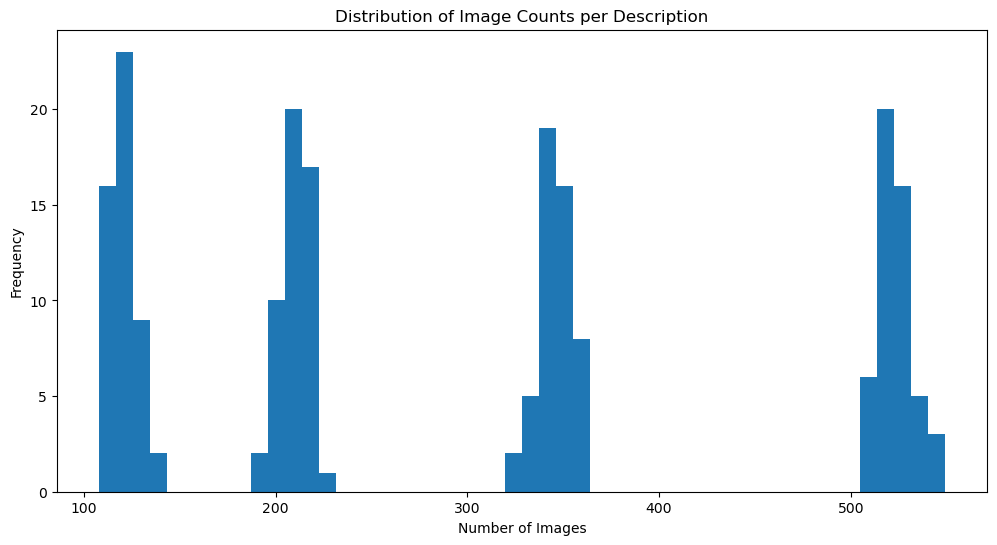

In [76]:
counts = labels["description"].value_counts()

plt.figure(figsize=(12, 6))
plt.hist(counts.values, bins=50)
plt.xlabel("Number of Images")
plt.ylabel("Frequency")
plt.title("Distribution of Image Counts per Description")
plt.show()

In [77]:
max_image_count =counts.max()
max_image_count

549

In [78]:
min_image_count = counts.min()
min_image_count

108

In [79]:
ratio_image_count = max_image_count / min_image_count
ratio_image_count

5.083333333333333

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> the largest class has ~5.1× more images than the smallest (549 vs 108). During training, the model therefore sees some classes about 5 times more often than others, so it may learn their patterns better.
</div>

In [80]:
mean = counts.mean()
mean

np.float64(300.0)

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> Unevenly distributed, we can see 4 clusters of distributions of our images per description
</div>



In [81]:
cluster_1 = (counts < 150).sum()
cluster_2 = ((counts >= 150) & (counts < 300)).sum()
cluster_3 = ((counts >= 300) & (counts < 500)).sum()
cluster_4 = (counts >= 500).sum()

print(f"Cluster 1 (less than 150 images): {cluster_1} classes")
print(f"Cluster 2 (150 to 299 images): {cluster_2} classes")
print(f"Cluster 3 (300 to 499 images): {cluster_3} classes")
print(f"Cluster 4 (500 or more images): {cluster_4} classes")


Cluster 1 (less than 150 images): 50 classes
Cluster 2 (150 to 299 images): 50 classes
Cluster 3 (300 to 499 images): 50 classes
Cluster 4 (500 or more images): 50 classes


<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> Evenly unevenly distributed
</div>

<h1 style="color:#2c5364; border-bottom:2px solid #2c5364; padding-bottom:4px;">Images exploration</h1>

In [82]:
path = r'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images'

In [83]:
file_names = labels["filename"].tolist()


In [84]:
images_paths = [os.path.join(path, f"{file_name}") for file_name in file_names]

In [85]:
def see_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    plt.figure(figsize=(4,4))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

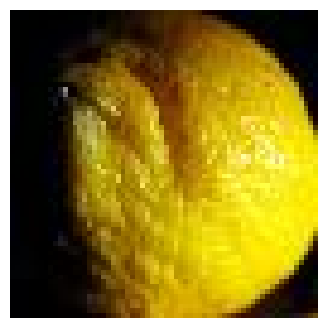

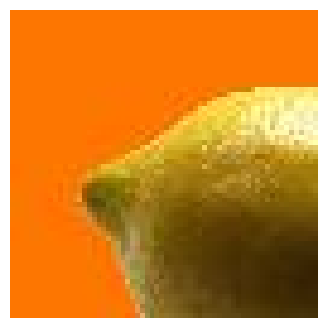

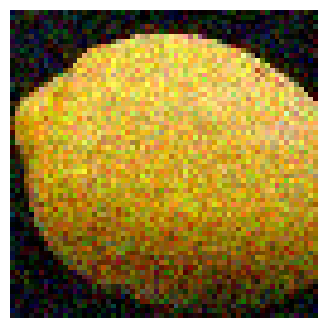

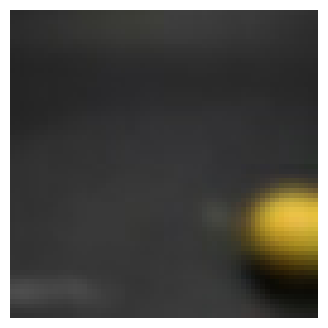

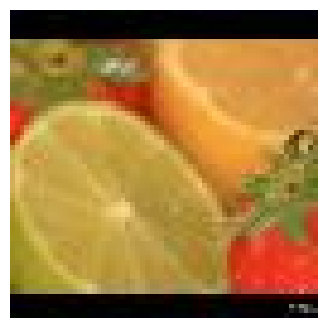

In [86]:
for i in range(1000, 1005):
    see_image(images_paths[i])

<h3 style="color:#2c5364; padding-bottom:3px;">Confirm if we can see every image and it's shape</h3>

In [87]:
def get_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = image / 255
    return image

In [88]:
flag = True
for i in range(len(images_paths)):
    try:
        image = get_image(images_paths[i])
        if image.shape != (64, 64, 3):
            flag = False
            break
    except Exception as e:
        print(f"Error loading image {images_paths[i]}: {e}")
        flag = False
        break
print(flag)

True


<h3 style="color:#2c5364; padding-bottom:3px;">Check duplicate images</h3>

In [89]:
import hashlib

def turn_into_hash_string(image_path):
    raw = tf.io.read_file(image_path) #Get the raw bytes of the image in the file
    image = tf.io.decode_jpeg(raw, channels=3) # Decode the raw bytes into a tensor 
    numpy_array_image = image.numpy() # Convert the tensor into a numpy array
    bytes_image = numpy_array_image.tobytes() # Convert the numpy array into bytes
    mixer_image = hashlib.md5(bytes_image) # Create a hash object, like a class object, using the MD5 algorithm and update it with the bytes of the image
    image_into_text = mixer_image.hexdigest() # Get the hexadecimal representation of the hash, which is just a string of characters that uniquely identifies the image
    return image_into_text

labels["hash"] = [turn_into_hash_string(p) for p in images_paths] # fingerprint of every image (about a minute) 

In [90]:
labels["is_duplicate"] = labels["hash"].duplicated(keep=False)           # True for EVERY copy of a repeated fingerprint
labels["n_labels"] = labels.groupby("hash")["class_id"].transform("nunique")  # different labels per fingerprint group (>1 = conflict)

print("Images involved in duplicates:", labels["is_duplicate"].sum())          # how many images have an identical twin
print("Images with conflicting labels:", (labels["n_labels"] > 1).sum())       # same picture, different labels

conflicts = labels[labels["n_labels"] > 1].sort_values("hash")                 # conflicting ones, twins side by side
conflicts                                                         

Images involved in duplicates: 12
Images with conflicting labels: 12


,filename,class_id,description,hash,is_duplicate,n_labels
27766,image_027767.JPEG,n03404251,fur coat,0f400b529da4df75a409602c4c5e7db8,True,2
47291,image_047292.JPEG,n02988304,CD player,0f400b529da4df75a409602c4c5e7db8,True,2
593,image_000594.JPEG,n03891332,parking meter,37bfb8e5b32c68152bfc8d2c7a53ee0b,True,2
13623,image_013624.JPEG,n07747607,orange,37bfb8e5b32c68152bfc8d2c7a53ee0b,True,2
11907,image_011908.JPEG,n01950731,"sea slug, nudibranch",3a7055e30d47b66c38cf3872564d9ddc,True,2
30312,image_030313.JPEG,n01945685,slug,3a7055e30d47b66c38cf3872564d9ddc,True,2
15109,image_015110.JPEG,n03584254,iPod,55985fcb729f347a8edf056fa147fb07,True,2
48341,image_048342.JPEG,n04254777,sock,55985fcb729f347a8edf056fa147fb07,True,2
1090,image_001091.JPEG,n07749582,lemon,59f2a108dfe8ec55424f514f2ff96a1c,True,2
59133,image_059134.JPEG,n07753592,banana,59f2a108dfe8ec55424f514f2ff96a1c,True,2


Image with index 27766 label is fur coat, the image is the following:


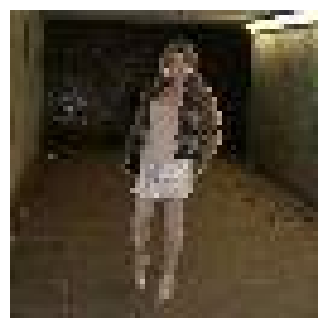

Image with index 47291 label is CD player, the image is the following:


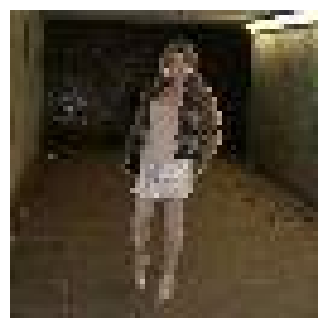

Image with index 593 label is parking meter, the image is the following:


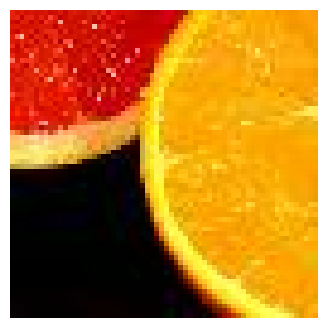

Image with index 13623 label is orange, the image is the following:


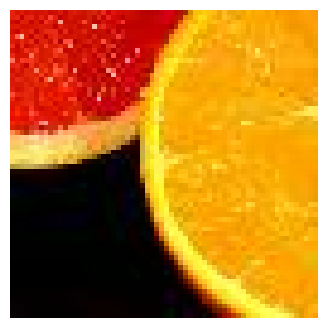

Image with index 11907 label is sea slug, nudibranch, the image is the following:


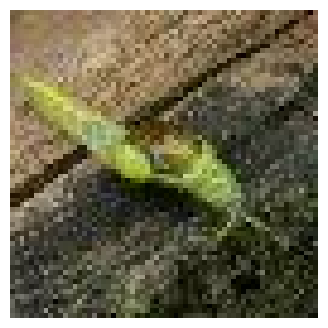

Image with index 30312 label is slug, the image is the following:


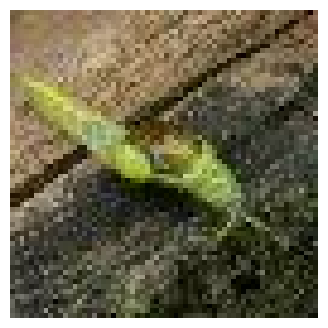

Image with index 15109 label is iPod, the image is the following:


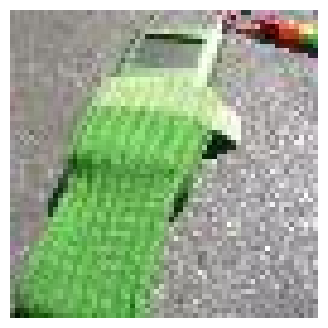

Image with index 48341 label is sock, the image is the following:


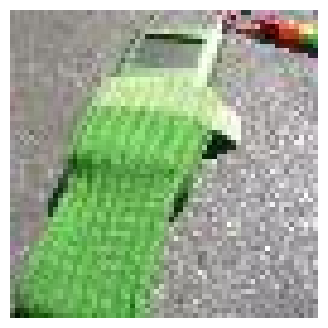

Image with index 1090 label is lemon, the image is the following:


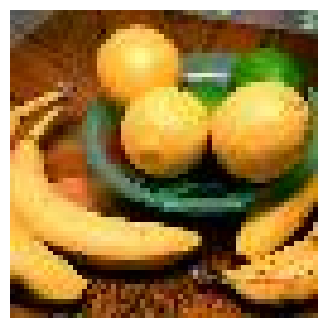

Image with index 59133 label is banana, the image is the following:


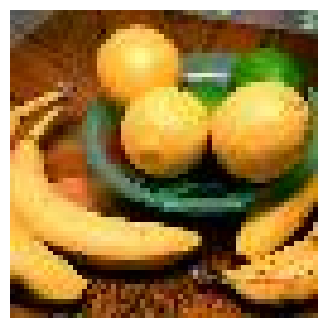

Image with index 33613 label is spiny lobster, langouste, rock lobster, crawfish, crayfish, sea crawfish, the image is the following:


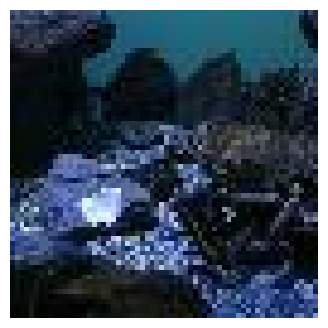

Image with index 40382 label is American lobster, Northern lobster, Maine lobster, Homarus americanus, the image is the following:


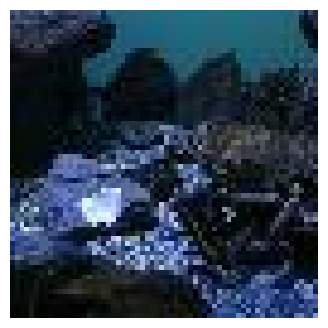

In [91]:
for i in conflicts.index:                                        # i = the row labels (e.g. 1503, 8821, ...)
    print(f"Image with index {i} label is {conflicts.loc[i, "description"]}, the image is the following:")
    see_image(os.path.join(path, conflicts.loc[i, "filename"])) # look up that row's filename

<div style="border-left:4px solid #2c5364; background:#2c536422; padding:8px 14px; border-radius:4px;">
<b>Note:</b> The first 2 images are defensible the rest is very subjective
</div>

<h3 style="color:#2c5364; padding-bottom:3px;">Randomly check the images descriptions</h3>

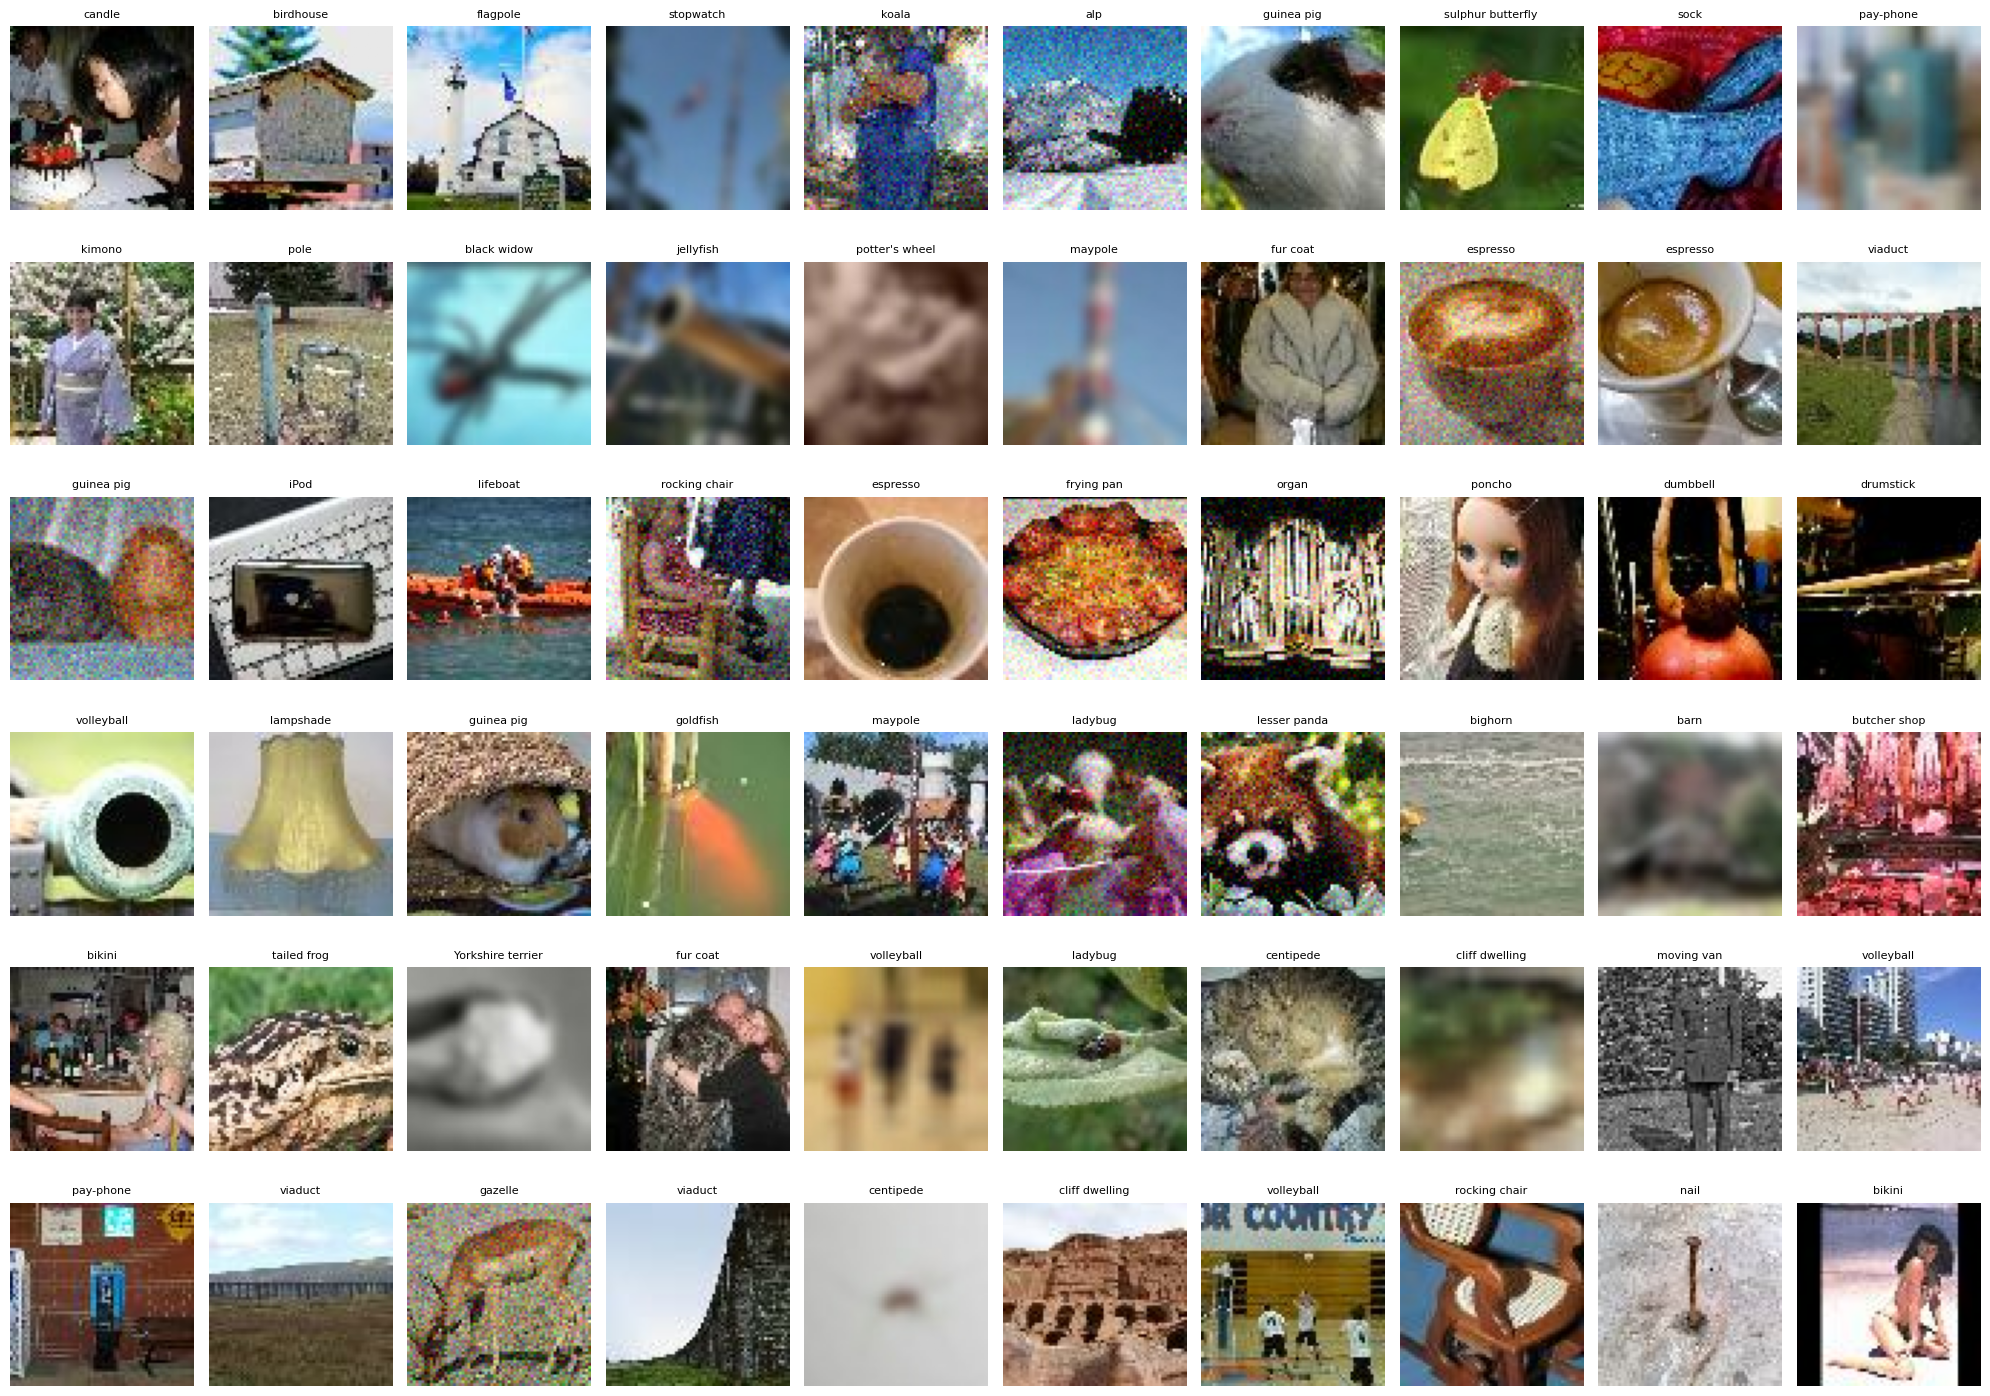

In [92]:
random.seed(42)

percentage_of_images = 0.001

number_of_samples = int(len(labels)*percentage_of_images)
random_images = random.sample(range(len(labels)), number_of_samples)

number_of_columns = 10                                              
number_of_rows = -(-number_of_samples // number_of_columns)   # Just to round up if the number is not exact, if it was possitive it would round down                     

plt.figure(figsize=(20, 2.4 * number_of_rows))
for i, random_index in enumerate(random_images):
    dataset_row = labels.iloc[random_index]
    image = get_image(os.path.join(path, dataset_row["filename"]))

    plt.subplot(number_of_rows, number_of_columns, i+1)
    plt.imshow(image)
    plt.title(dataset_row["description"].split(",")[0], fontsize = 8)
    plt.axis("off")

plt.tight_layout()
plt.show()